In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import nibabel as nib
import torch
from torch.utils.data import Dataset, DataLoader
from scipy import stats

c:\Users\juan_\AppData\Local\Programs\Python\Python310\lib\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.25.905) or chardet (7.6.0)/charset_normalizer (3.4.4) doesn't match a supported version!
  warnings.warn(


In [ ]:
# ==========================================
# 1. CLINICAL EDA FOR COBRE DATASET
# ==========================================
csv_path = r"C:\Users\juan_\Desktop\cv-medical\COBRE_Dataset\participants.tsv"

if os.path.exists(csv_path):
    df_participants = pd.read_csv(csv_path, sep='\t')
    print("--- Primeras filas del registro clínico ---")
    print(df_participants[['participant_id', 'age', 'gender', 'diagnosis']].head())
    
    # Class count for column: 'diagnosis'
    if 'diagnosis' in df_participants.columns:
        class_counts = df_participants['diagnosis'].value_counts()
        print("\n--- Class Distribution (Diagnosis) ---")
        print(class_counts)
else:
    print("Make sure the participants.tsv file is in the correct path.")

--- Primeras filas del registro clínico ---
  participant_id  age gender diagnosis
0      sub-10159   30      F   CONTROL
1      sub-10171   24      M   CONTROL
2      sub-10189   49      M   CONTROL
3      sub-10193   40      M   CONTROL
4      sub-10206   21      M   CONTROL

--- Class Distribution (Diagnosis) ---
diagnosis
CONTROL    130
SCHZ        50
BIPOLAR     49
ADHD        43
Name: count, dtype: int64


In [3]:
# ==========================================
# 2. PYTORCH CUSTOM DATASET 
# ==========================================
class COBREMRI2DDataset(Dataset):
    def __init__(self, data_dir, df_metadata, transform=None):
        self.data_dir = data_dir
        self.transform = transform
        self.subjects = []
        self.labels = []
        
        # Mapping of diagnosis to number (e.g., CONTROL = 0, Schizophrenia/Patient = 1)
        # We will verify the unique values of diagnosis later, for now we save the ID
        for idx, row in df_metadata.iterrows():
            pid = row['participant_id']
            subject_path = os.path.join(self.data_dir, pid, "anat", f"{pid}_T1w.nii.gz")
            if os.path.exists(subject_path):
                self.subjects.append(pid)
                # Save the diagnosis label
                diag = row['diagnosis']
                self.labels.append(0 if diag == 'CONTROL' else 1)
                
        print(f"\nDataset initialized with {len(self.subjects)}  valid subjects found.")

    def __len__(self):
        return len(self.subjects)

    def __getitem__(self, idx):
        subject_id = self.subjects[idx]
        label = self.labels[idx]
        img_path = os.path.join(self.data_dir, subject_id, "anat", f"{subject_id}_T1w.nii.gz")
        
        # 1. Load 3D volume with nibabel
        nii_img = nib.load(img_path)
        volume = nii_img.get_fdata()
        
        # 2. Z-Score normalization (Standard in medical images)
        volume = (volume - np.mean(volume)) / (np.std(volume) + 1e-8)
        
        # 3. Extract the central axial slice (2D slice)
        slice_idx = volume.shape[2] // 2
        slice_2d = volume[:, :, slice_idx]
        
        # Convert to PyTorch tensor [Channel=1, Height, Width]
        tensor_slice = torch.tensor(slice_2d, dtype=torch.float32).unsqueeze(0)
        
        return tensor_slice, torch.tensor(label, dtype=torch.long)

In [4]:
# Instance and test the DataLoader
dataset = COBREMRI2DDataset(data_dir=r"C:\Users\juan_\Desktop\cv-medical\COBRE_Dataset", df_metadata=df_participants)
dataloader = DataLoader(dataset, batch_size=4, shuffle=True)

# Test a quick batch with labels
for batch_images, batch_labels in dataloader:
    print(f"\n Batch Shape: {batch_images.shape}") # Expected: torch.Size([4, 1, 256, 256])
    print(f" Batch Labels (0: Control, 1: Patient): {batch_labels}")
    break


Dataset initialized with 265  valid subjects found.

 Batch Shape: torch.Size([4, 1, 176, 256])
 Batch Labels (0: Control, 1: Patient): tensor([0, 0, 1, 1])


## Stadistical Analysis

In [5]:
import seaborn as sns

In [6]:
csv_path = r"C:\Users\juan_\Desktop\cv-medical\COBRE_Dataset\participants.tsv"
df = pd.read_csv(csv_path, sep='\t')

In [7]:
# 1. Load clinical metadata
csv_path = r"C:\Users\juan_\Desktop\cv-medical\COBRE_Dataset\participants.tsv"
df = pd.read_csv(csv_path, sep='\t')

print("==================================================")
print("       STATISTICAL AND DEMOGRAPHIC STUDY OF COBRE    ")
print("==================================================\n")

# 2. Summary of diagnoses
print("--- Count and Proportion by Diagnosis ---")
diag_counts = df['diagnosis'].value_counts()
diag_percent = df['diagnosis'].value_counts(normalize=True) * 100
summary_diag = pd.DataFrame({'Count': diag_counts, 'Percentage (%)': diag_percent})
print(summary_diag)
print(f"\nTotal of subjects in the clinical table: {len(df)}")

# 3. Descriptive statistics of Age by Group
print("\n--- Age Statistics (Mean, Std, Median, IQR) ---")
age_stats = df.groupby('diagnosis')['age'].agg(
    n='count',
    Mean='mean',
    Std='std',
    Median='median',
    IQR=lambda x: np.percentile(x, 75) - np.percentile(x, 25)
)
print(age_stats.round(2))

       STATISTICAL AND DEMOGRAPHIC STUDY OF COBRE    

--- Count and Proportion by Diagnosis ---
           Count  Percentage (%)
diagnosis                       
CONTROL      130       47.794118
SCHZ          50       18.382353
BIPOLAR       49       18.014706
ADHD          43       15.808824

Total of subjects in the clinical table: 272

--- Age Statistics (Mean, Std, Median, IQR) ---
             n   Mean    Std  Median    IQR
diagnosis                                  
ADHD        43  33.09  10.76    30.0  21.00
BIPOLAR     49  35.29   9.03    36.0  17.00
CONTROL    130  31.26   8.74    28.0  15.00
SCHZ        50  36.46   8.88    37.5  14.75


In [8]:
# 4. Statistical hypothesis testing (ANOVA for multiple groups in Age)
# Extract the lists of ages for each present diagnosis group
age_groups_list = [group['age'].dropna().values for name, group in df.groupby('diagnosis')]
f_stat, p_val_anova = stats.f_oneway(*age_groups_list)

print(f"\nANOVA Test (Age between the 4 groups): F = {f_stat:.4f}, p-value = {p_val_anova:.4f}")
if p_val_anova < 0.05:
    print("⚠️ Statistical Alert: There are significant differences in age between at least one of the groups (variable to consider).")
else:
    print("✅ Ages are well distributed globally between the 4 groups (no significant differences).")

# 5. Gender Analysis (Contingency Table and Chi-square)
print("\n--- Gender Distribution by Diagnosis ---")
contingency_table = pd.crosstab(df['diagnosis'], df['gender'], margins=True)
print(contingency_table)

chi2, p_chi, dof, ex = stats.chi2_contingency(pd.crosstab(df['diagnosis'], df['gender']))
print(f"\nChi-square Test of Independence (Gender vs Diagnosis): p-value = {p_chi:.4f}")


ANOVA Test (Age between the 4 groups): F = 4.9001, p-value = 0.0025
⚠️ Statistical Alert: There are significant differences in age between at least one of the groups (variable to consider).

--- Gender Distribution by Diagnosis ---
gender       F    M  All
diagnosis               
ADHD        22   21   43
BIPOLAR     21   28   49
CONTROL     62   68  130
SCHZ        12   38   50
All        117  155  272

Chi-square Test of Independence (Gender vs Diagnosis): p-value = 0.0213


C:\Users\juan_\AppData\Local\Temp\ipykernel_12140\941828578.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='diagnosis', y='age', data=df, palette='Set2', ax=axes[0], width=0.4, boxprops=dict(alpha=0.8))


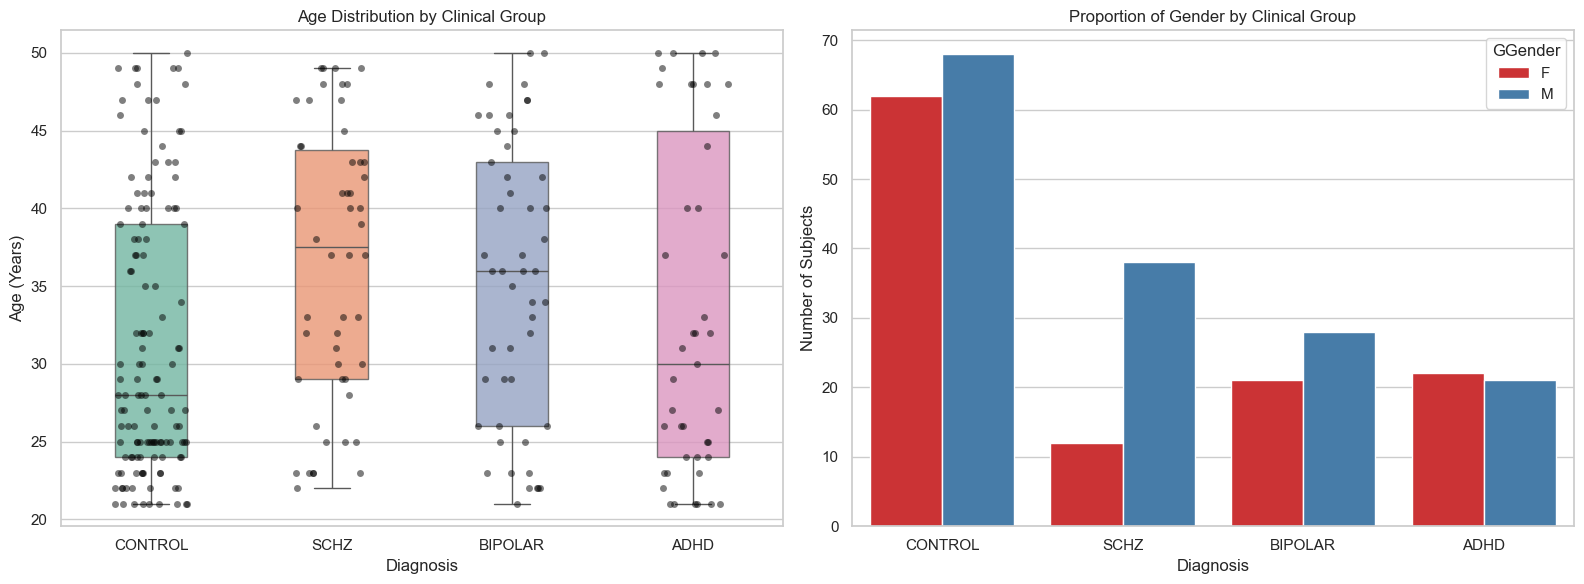

In [9]:
# ==========================================
# 6. VISUALIZATION OF THE REPORT 
# ==========================================
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Graph 1: Boxplot of Age by Diagnosis
sns.boxplot(x='diagnosis', y='age', data=df, palette='Set2', ax=axes[0], width=0.4, boxprops=dict(alpha=0.8))
sns.stripplot(x='diagnosis', y='age', data=df, color='black', alpha=0.5, jitter=0.2, ax=axes[0])
axes[0].set_title('Age Distribution by Clinical Group')
axes[0].set_xlabel('Diagnosis')
axes[0].set_ylabel('Age (Years)')

# Graph 2: Proportion of Gender by Diagnosis
sns.countplot(x='diagnosis', hue='gender', data=df, palette='Set1', ax=axes[1])
axes[1].set_title('Proportion of Gender by Clinical Group')
axes[1].set_xlabel('Diagnosis')
axes[1].set_ylabel('Number of Subjects')
axes[1].legend(title='GGender')

plt.tight_layout()
plt.show()